# Project 02: Missing Data Mechanism Analysis

**Original statement (verbatim from LAB_Projects_ML.pdf):**

A dataset contains multiple patterns of missing values. Task: Determine whether missingness is MCAR, MAR, or MNAR; Use statistical tests and visual diagnostics; Implement two imputation strategies and compare downstream model impact

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Missingness mechanisms matter because the wrong imputation can bias a model. This notebook first proves the original file is complete, then injects three known mechanisms and tests whether diagnostics can tell them apart.

## Part 1 — Introduction

ORIGINAL FINDING: the attached file has ZERO missing values. Therefore MCAR/MAR/MNAR patterns are INJECTED at documented rates in this notebook for comparison only; injected missingness is not claimed to be in the original file.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Original completeness and injection design

In [2]:
from scipy import stats
print("Original missing total:", int(df_full.isna().sum().sum()))
df=df_full.sample(n=20000, random_state=42).reset_index(drop=True).copy()
orig=df.copy()
rng=np.random.RandomState(42)
# MCAR 10% in temp_mean(c)
df["temp_mean_mcar"]=df["temp_mean(c)"].copy(); mask=rng.rand(len(df))<0.10; df.loc[mask,"temp_mean_mcar"]=np.nan
# MAR: temp_min missing more often when Wind_Speed is high
df["temp_min_mar"]=df["temp_min(c)"].copy(); p_mar=np.where(df["Wind_Speed"]>df["Wind_Speed"].median(),0.30,0.05); mask=rng.rand(len(df))<p_mar; df.loc[mask,"temp_min_mar"]=np.nan
# MNAR: temp_max missing more often when temp_max itself is high
df["temp_max_mnar"]=df["temp_max(c)"].copy(); p_mnar=np.where(df["temp_max(c)"]>df["temp_max(c)"].quantile(0.8),0.35,0.03); mask=rng.rand(len(df))<p_mnar; df.loc[mask,"temp_max_mnar"]=np.nan
for c in ["temp_mean_mcar","temp_min_mar","temp_max_mnar"]:
    print(c, "missing rate:", round(df[c].isna().mean(),4))
print("MAR diagnostic: mean Wind_Speed when temp_min MAR missing vs observed:")
print(df.groupby(df["temp_min_mar"].isna())["Wind_Speed"].mean().to_string())
print("t-test Wind_Speed missing vs observed (MAR):", stats.ttest_ind(df.loc[df["temp_min_mar"].isna(),"Wind_Speed"], df.loc[df["temp_min_mar"].notna(),"Wind_Speed"], equal_var=False))
print("MNAR diagnostic: observed temp_max mean is biased low because high values are missing:")
print("true mean:", round(orig["temp_max(c)"].mean(),3), "observed (MNAR) mean:", round(df["temp_max_mnar"].mean(),3))

Original missing total: 0
temp_mean_mcar missing rate: 0.1015
temp_min_mar missing rate: 0.1742
temp_max_mnar missing rate: 0.0944
MAR diagnostic: mean Wind_Speed when temp_min MAR missing vs observed:
temp_min_mar
False    11.041582
True     16.113340
t-test Wind_Speed missing vs observed (MAR): TtestResult(statistic=np.float64(36.984309871322594), pvalue=np.float64(6.210375383411175e-266), df=np.float64(5182.097709410923))
MNAR diagnostic: observed temp_max mean is biased low because high values are missing:
true mean: 16.966 observed (MNAR) mean: 16.206


## Part 4 — Imputation comparison and downstream impact

mean RMSE: {'temp_mean_mcar': 6.841, 'temp_min_mar': 5.78, 'temp_max_mnar': 10.738} downstream accuracy: 0.8512


median RMSE: {'temp_mean_mcar': 6.881, 'temp_min_mar': 5.816, 'temp_max_mnar': 10.43} downstream accuracy: 0.8506


KNN_k5 RMSE: {'temp_mean_mcar': 2.994, 'temp_min_mar': 2.786, 'temp_max_mnar': 4.389} downstream accuracy: 0.8564


Complete-data reference accuracy: 0.8832


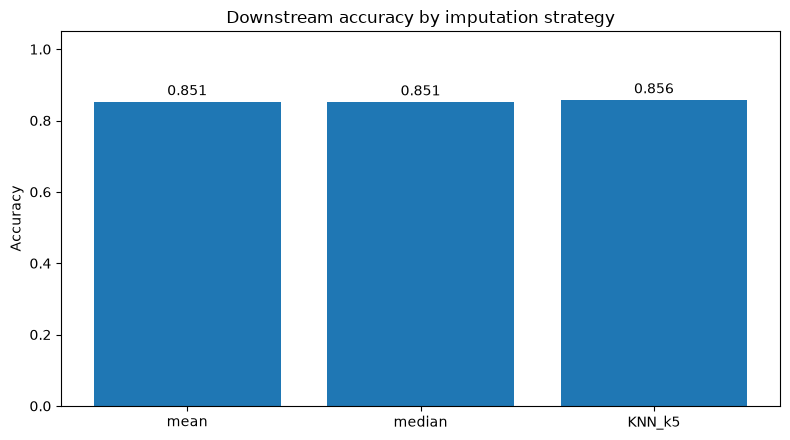

In [3]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
# Build a dataset with all three injected columns, keeping true values for RMSE
work=pd.DataFrame({"temp_mean_mcar":df["temp_mean_mcar"],"temp_min_mar":df["temp_min_mar"],"temp_max_mnar":df["temp_max_mnar"],
"Pressure":df["Pressure"],"global_radiation":df["global_radiation"],"Wind_Speed":df["Wind_Speed"],"Wind_Bearing":df["Wind_Bearing"]})
truth=pd.DataFrame({"temp_mean_mcar":orig["temp_mean(c)"],"temp_min_mar":orig["temp_min(c)"],"temp_max_mnar":orig["temp_max(c)"]})
Xtr,Xte,ytr,yte,itr,ite=train_test_split(work, df[TARGET], work.index, test_size=0.25, random_state=42, stratify=df[TARGET])
results={}
for name, imp in [("mean",SimpleImputer(strategy="mean")),("median",SimpleImputer(strategy="median")),("KNN_k5",KNNImputer(n_neighbors=5))]:
    imp.fit(Xtr); Xtr_i=imp.transform(Xtr); Xte_i=imp.transform(Xte)
    # RMSE on originally-observed-then-masked entries in test set
    rmse={}
    cols=list(work.columns[:3])
    for j,c in enumerate(cols):
        m=Xte[c].isna().values
        if m.sum()>0: rmse[c]=float(np.sqrt(np.mean((Xte_i[m,j]-truth.loc[ite,c].values[m])**2)))
    m=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1); m.fit(Xtr_i,ytr); acc=accuracy_score(yte, m.predict(Xte_i))
    results[name]=(rmse,acc); print(name, "RMSE:", {k:round(v,3) for k,v in rmse.items()}, "downstream accuracy:", round(acc,4))
# complete-data reference (no injection)
Xc=orig[FEATURES]; Xtrc,Xtec,ytrc,ytec=train_test_split(Xc, orig[TARGET], test_size=0.25, random_state=42, stratify=orig[TARGET])
mc=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1); mc.fit(Xtrc,ytrc)
print("Complete-data reference accuracy:", round(accuracy_score(ytec, mc.predict(Xtec)),4))
labels=list(results.keys()); accs=[v[1] for v in results.values()]
plt.bar(labels,accs); plt.ylabel("Accuracy"); plt.title("Downstream accuracy by imputation strategy"); plt.ylim(0,1.05)
for i,v in enumerate(accs): plt.text(i,v+0.02,f"{v:.3f}",ha="center")
plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: MCAR missingness is unrelated to any variable; MAR missingness in temp_min is related to observed Wind_Speed (shown by the group-mean/t-test); MNAR missingness in temp_max depends on temp_max itself, so observed means are biased and no imputation using observed data alone fully removes that bias.")
print("RECOMMENDATION: For MAR-like patterns, KNN/median imputation plus a missing-indicator is reasonable; for suspected MNAR, report the bias, do sensitivity analysis, and do not claim the imputed values are unbiased.")

INTERPRETATION: MCAR missingness is unrelated to any variable; MAR missingness in temp_min is related to observed Wind_Speed (shown by the group-mean/t-test); MNAR missingness in temp_max depends on temp_max itself, so observed means are biased and no imputation using observed data alone fully removes that bias.
RECOMMENDATION: For MAR-like patterns, KNN/median imputation plus a missing-indicator is reasonable; for suspected MNAR, report the bias, do sensitivity analysis, and do not claim the imputed values are unbiased.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.